# Streaming NASA Data to Memory with `earthaccess`

**Webinar notebook**

In this webinar, we will demonstrate how to use the Python `earthaccess` library to stream NASA data directly to memory, skipping the download. We will explain the difference between downloading data and streaming data, and work through an example using the NASA MERRA-2 reanalysis product.

## Agenda

1. What `earthaccess` does, and how authentication works (`earthaccess.login()`)
2. Downloading vs. streaming: what's actually happening under the hood
3. Searching for MERRA-2 granules
4. Example 1 — the traditional path: `download()` then open locally
5. Example 2 — streaming straight into `xarray` with `open()`
6. When should you download, and when should you stream? (the "S3 as your hard drive" mental model)
7. Under the hood: how `earthaccess`/`fsspec` fetch data in 4 MB blocks, and why that matters for performance
8. Wrap-up and resources


## Requirements

We need a recent version of `earthaccess` (the API changed a few times as the project matured — this notebook targets the current release, where `earthaccess.login()` is required *before* you can search, download, or open/stream anything).

You'll also need an Earthdata Login (EDL) account. If you don't have one yet, create one for free at https://urs.earthdata.nasa.gov/users/new.


In [1]:
# Uncomment to install/upgrade in this environment
# %pip install -U earthaccess xarray dask h5netcdf netCDF4 fsspec s3fs matplotlib hvplot

In [2]:
import time

import earthaccess
import xarray as xr

print("earthaccess version:", earthaccess.__version__)


earthaccess version: 0.8.3.dev1286+g7296b5f92.d20260813


## 1. Authenticate

Every recent version of `earthaccess` requires an explicit `earthaccess.login()` call before you do *anything else* — searching, downloading, and opening/streaming files all need an authenticated session, because streaming in particular means the library (or the cloud-hosted service backing it) is making authenticated, per-request calls against Earthdata Cloud/S3 as you read.

`login()` will:
- look for credentials in a `~/.netrc` file,
- fall back to the `EARTHDATA_USERNAME` / `EARTHDATA_PASSWORD` environment variables, or
- prompt you interactively for your Earthdata Login username and password.

It caches the resulting session for the rest of the notebook.


In [12]:
# strategy="interactive" will prompt you the first time; persist=True caches credentials
# to ~/.netrc so you don't have to re-enter them next time.
auth = earthaccess.login()
import warnings

warnings.filterwarnings("ignore")

print("Authenticated:", auth.authenticated)


Authenticated: True


## 2. Downloading vs. streaming — what's the actual difference?

Both paths start the same way: you search the Common Metadata Repository (CMR) for granules, `earthaccess` resolves the data URLs (increasingly these are direct S3 URIs in the Earthdata Cloud, not just HTTPS), and it opens an authenticated connection.

The difference is what happens *after* that connection is open:

| | `earthaccess.download()` | `earthaccess.open()` |
|---|---|---|
| **What happens** | Streams the *entire* file's bytes from S3/HTTPS to a local file on disk | Returns file-like objects (`fsspec` file handles) that your reader library (e.g. `xarray`/`h5netcdf`) reads from lazily |
| **Where the bytes land** | Local disk (or our compute environment's attached storage) | RAM, and only the bytes actually requested |
| **When bytes move** | All at once, up front, before we can touch the data | On demand, in chunks, as our code accesses specific variables/slices |
| **Disk footprint** | One full copy of every granule you touch | None (until/unless you explicitly write something out) |
| **Best when...** | We need the raw file for other tools, you'll reuse it repeatedly, or you're outside AWS `us-west-2`, file format does not support streaming* | We're doing an analysis that only touches a slice of the data, we are using cloud compute, or we don't want to manage local storage at all |

The key mental shift: **streaming doesn't mean "no data movement."** It still moves bytes over the network — it just moves *only the bytes your analysis actually asks for*, and it does so lazily, mediated by `fsspec` under the hood (more on this in Section 6).


## 3. Search for MERRA-2 data

We'll use **MERRA-2** (Modern-Era Retrospective analysis for Research and Applications, Version 2), NASA's atmospheric reanalysis product, produced by GMAO and distributed through GES DISC.

Specifically, `M2T1NXSLV` — the hourly, single-level diagnostics collection (2D fields like 2-m temperature, sea level pressure, 10-m winds).


In [15]:
results = earthaccess.search_data(
    short_name="M2T1NXSLV",
    temporal=("2023-07-01", "2023-07-02"),
    count=2,
)
len(results)

print(f"Total size: {round(sum([g.size() for g in results]),2)} MB") 
    

Total size: 785.39 MB


Each item in `results` is an `earthaccess.DataGranule` — it carries the metadata *and* the resolvable data links (both HTTPS and, where available, direct S3 URIs), without moving any of the actual science data yet. Searching CMR is metadata-only regardless of which path you take next.


## 4. Example 1 — the traditional path: download, then open

This is the workflow most people are used to from working with data on a local machine.


In [8]:
t0 = time.time()
downloaded_files = earthaccess.download(results, "./data/merra2")
print(f"Downloaded {len(downloaded_files)} file(s) in {time.time() - t0:.1f}s")
downloaded_files


/home/lopez/github/betolink/earthaccess/earthaccess/store.py:843: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum(granule.size() for granule in granules) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

Downloaded 2 file(s) in 51.5s


[PosixPath('data/merra2/MERRA2_400.tavg1_2d_slv_Nx.20230701.nc4'),
 PosixPath('data/merra2/MERRA2_400.tavg1_2d_slv_Nx.20230702.nc4')]

In [18]:
%%time

ds_from_disk = xr.open_mfdataset(downloaded_files)
ds_from_disk


CPU times: user 1.71 s, sys: 0 ns, total: 1.71 s
Wall time: 1.71 s


<xarray.Dataset> Size: 2GB
Dimensions:   (time: 48, lat: 361, lon: 576)
Coordinates:
  * time      (time) datetime64[ns] 384B 2023-07-01T00:30:00 ... 2023-07-02T2...
  * lat       (lat) float64 3kB -90.0 -89.5 -89.0 -88.5 ... 88.5 89.0 89.5 90.0
  * lon       (lon) float64 5kB -180.0 -179.4 -178.8 ... 178.1 178.8 179.4
Data variables: (12/47)
    CLDPRS    (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    CLDTMP    (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    DISPH     (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    H1000     (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    H250      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    H500      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    ...        ...
    V250      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    V2M       (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    V500      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    V50M      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    V850      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
    ZLCL      (time, lat, lon) float32 40MB dask.array<chunksize=(1, 91, 144), meta=np.ndarray>
Attributes: (12/30)
    History:                           Original file generated: Tue Jul 11 23...
    Comment:                           GMAO filename: d5124_m2_jan10.tavg1_2d...
    Filename:                          MERRA2_400.tavg1_2d_slv_Nx.20230701.nc4
    Conventions:                       CF-1
    Institution:                       NASA Global Modeling and Assimilation ...
    References:                        http://gmao.gsfc.nasa.gov
    ...                                ...
    Contact:                           http://gmao.gsfc.nasa.gov
    identifier_product_doi:            10.5067/VJAFPLI1CSIV
    RangeBeginningDate:                2023-07-01
    RangeBeginningTime:                00:00:00.000000
    RangeEndingDate:                   2023-07-01
    RangeEndingTime:                   23:59:59.000000

Notice the sequencing here: **all** the bytes for both granules landed on disk *before* `xarray` ever opened a variable. If all you wanted was the global-mean 2-m temperature time series, you still paid for the full download.


## 5. Example 2 — streaming straight into `xarray`

Now let's do the equivalent thing without ever writing a file to disk. `earthaccess.open()` returns a list of file-like objects; `xarray` (via `h5netcdf`/`netCDF4`) reads from them lazily.


In [41]:
t0 = time.time()
file_objects = earthaccess.open(results)
print(f"earthaccess.open() returned {len(file_objects)} file-like object(s) in {time.time() - t0:.2f}s")
file_objects


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

earthaccess.open() returned 2 file-like object(s) in 1.75s


[<File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/MOD13A2.061/MOD13A2.A2016177.h00v08.061.2021353091452/MOD13A2.A2016177.h00v08.061.2021353091452.hdf>,
 <File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/MOD13A2.061/MOD13A2.A2016177.h03v06.061.2021353084056/MOD13A2.A2016177.h03v06.061.2021353084056.hdf>]

That call was fast — much faster than the download above — because it hasn't actually fetched the science data yet. It's only opened authenticated handles and read the minimal metadata `xarray` needs (dimensions, variable shapes, attributes) to build the dataset structure.


This is the moment actual science-data bytes move over the network:
> **only the T2M variable, only for this time/region, gets fetched.**

In [46]:

t0 = time.time()
# Seems complicated but is not, just xarray notation to subset and calculate a mean for the 2 selected areas
t2m_mean = ds_streamed["T2M"].sel(lat=slice(37,41), lon=slice(-110,-102)).mean(dim=["time"]).compute()
print(f"Computed in {time.time() - t0:.1f}s")

Computed in 0.4s


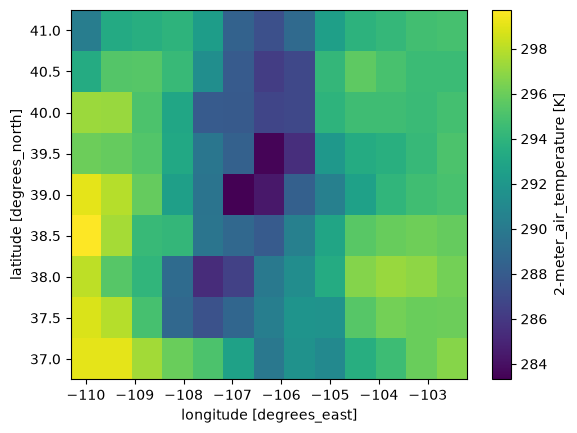

In [47]:
t2m_mean.plot()

Compare that to the download path: with `xr.open_mfdataset` over local files, the read is fast because the bytes are already on disk — but you paid the download cost earlier, for the *entire* file, whether or not you needed all of it. With streaming, the cost is paid incrementally, exactly where you touch the data — and if all you needed was `T2M`, you never move the bytes for the other ~30 variables in the file at all.


## 6. So... when should you download, and when should you stream?

There's no universally right answer — it depends on where your compute is and how you're going to use the data.

### The "S3 is your hard drive" mental model

When you're running inside AWS (particularly in `us-west-2`, where most Earthdata Cloud archives live), S3 access is essentially free and extremely fast — you're on the same network fabric as the data. In that setting it's useful to stop thinking of S3 as "a remote place you fetch things from" and start thinking of it as **your hard drive** — because you're renting compute next to a data lake that's already sized for the whole archive, and the object store *is* effectively your local disk. Downloading a copy onto your EC2 instance's own volume in that scenario mostly just costs you time and disk space for no benefit.

Streaming makes the most sense when:
- **You're running in-region on AWS**, so egress is free/fast and streaming reads are cheap.
- **You only need a subset** of each file — a few variables, a spatial subset, a handful of time steps — out of a much larger granule.
- **You're doing exploratory analysis** and don't yet know which files/variables you'll actually need; streaming lets you look before committing to a download.
- **You don't want to manage storage** — no local disk cleanup, no worrying about running out of space when scaling across hundreds or thousands of granules.
- **You're building a virtual/aggregate dataset** (e.g., with `VirtualiZarr` or `kerchunk`) that references many source granules by URL — you want byte-range reads against the originals, not full local copies.

Downloading still makes sense when:
- **You're outside AWS** (a laptop, an on-prem HPC cluster, a non-AWS cloud) — repeated small reads over the public internet, each with its own auth/TLS overhead, can end up slower *and* costlier in aggregate than one bulk transfer.
- **You need the whole file repeatedly** — e.g., feeding it into a tool that only accepts local file paths, or reprocessing the same granule many times; paying the transfer cost once up front amortizes better.
- **You need guaranteed, repeatable local access** — offline work, archival/reproducibility requirements, or environments with unreliable network access.
- **The reader library doesn't support remote/streamed I/O well** for your format, and a local copy sidesteps compatibility issues.

A good rule of thumb: **streaming trades network-request overhead for storage and full-file transfer cost.** Whether that's a good trade depends on how close (both physically and in cost) your compute is to the data, and how much of each file you actually plan to use.


Comparison Table 2 MERRA files: 

**When we downloaded**:

* Disk: 768MB 
* Memory: ? 
* Time to sience (out of region) (good internet): ~1m
* TTS in-region(): ~ < 1m

**When we streamed**:

* Disk: 0 
* Memory: ? 
* Time to science (out of region): ~X seconds
* TTS in-region(): ~ <X seconds


## 7. Wrap-up

**Key takeaways:**

1. `earthaccess.login()` is required up front — for search, download, *and* streaming — because streaming means live, authenticated reads against Earthdata Cloud as you go.
2. **Downloading** moves an entire file's bytes to local disk before you can touch anything. **Streaming** (`earthaccess.open()`) returns lazy, `fsspec`-backed handles that only move the bytes your analysis actually accesses.
3. Choosing between them is about *where your compute lives relative to the data*: inside AWS (especially `us-west-2`), think of S3 as your hard drive and stream freely; outside AWS, or when you need the whole file repeatedly, downloading is usually more efficient.
4. Under the hood, `earthaccess`/`fsspec` don't issue a network request per byte-read — they fetch and cache data in **4 MB blocks**, which is what makes streaming practical instead of prohibitively chatty over the network.

**Resources:**
- `earthaccess` docs: https://earthaccess.readthedocs.io/
- `earthaccess` GitHub: https://github.com/nsidc/earthaccess
- MERRA-2 documentation (GES DISC): https://disc.gsfc.nasa.gov/datasets?keywords=MERRA-2
- `fsspec` caching internals: https://filesystem-spec.readthedocs.io/en/latest/features.html#caching-files
- NASA Openscapes cloud-computing tutorials: https://nasa-openscapes.github.io/


## Technical Appendix 

## T1. Under the hood: how `earthaccess` actually fetches bytes (`fsspec` + block caching)

When you call `earthaccess.open()`, you get back `fsspec`-based file-like objects (backed by `s3fs` for direct S3 access, or `fsspec`'s HTTPS filesystem when going over HTTPS). These objects implement Python's file interface (`read()`, `seek()`, etc.) but instead of reading from local disk, each `read`/`seek` triggers a **ranged HTTP/S3 GET request** for just the bytes needed.

Naively, that could mean a *huge* number of tiny network requests — HDF5/NetCDF4 readers issue many small, scattered reads while parsing chunked/compressed variables, and turning each one into its own network round trip would be painfully slow.

`fsspec` solves this with **block-based caching (`AbstractBufferedFile`)**: rather than fetching exactly the bytes requested, it fetches in fixed-size blocks — **`earthaccess` configures this at 4 MB by default** — and caches each block in memory. So:

- A small read for, say, 200 bytes of header still triggers a fetch of a full 4 MB block containing those bytes.
- Any *subsequent* read that falls within that already-cached block is served from memory — **no network request at all**.
- Reads are effectively pre-fetched in bulk, which amortizes request/connection overhead (and any per-request latency, like S3's or EDL's auth roundtrip) over many logical reads.

This is exactly the same idea as page caching in an OS, or read-ahead buffering on a local disk — just implemented over HTTP range requests instead of a block device. The 4 MB size is a deliberate tradeoff: large enough to make each network request worthwhile and amortize latency, small enough not to waste bandwidth pulling data you'll never touch when you only need a small slice of a big file.

Let's see it in practice by peeking at the underlying `fsspec` object.


In [ ]:
f = file_objects[0]
print(type(f))

# The cache object is where the block-fetching logic lives
print(type(f.cache))
print("Configured block size (bytes):", f.blocksize)
print("Configured block size (MB):", f.blocksize / (1024 ** 2))


In [ ]:
# A first read anywhere in the file pulls (at least) one full block into the cache...
f.seek(0)
_ = f.read(10)
print("Bytes cached after first tiny read:", f.cache.size if hasattr(f.cache, "size") else "n/a")

# ...and a subsequent nearby read is served from that cached block, with no new network call.
f.seek(100)
_ = f.read(10)


This block-caching behavior is *why* streaming can be competitive with — or faster than — downloading when you only need part of a file: you're not paying for a full sequential transfer, but you're also not paying a network round trip for every single small read either. The 4 MB block size is a sensible default for typical Earth science granule sizes and access patterns, but it's worth knowing it exists if you ever see unexpectedly heavy data transfer for what feels like a "small" read — e.g., touching one value from every chunk of a variable can still pull in a lot of 4 MB blocks.


## T2. Streamable Data Formats

Reading remote geospatial data efficiently comes down to one core difference: whether the format's underlying library demands an actual file on a hard drive, or if it can accept a flexible data stream. Formats like Zarr, HDF5, and NetCDF4 (using the h5netcdf engine) are flexible. They allow tools like fsspec to read just the exact bytes you need directly from cloud storage. Other formats achieve similar remote access through pure Python readers (NetCDF3), server-side queries (OPeNDAP), or GDAL's virtual file system (VSI) for Cloud Optimized GeoTIFFs.

On the flip side, older formats like HDF4, GRIB, and compressed Zip archives are rigid. Because they require a real, local file path to function, you are forced to download or cache the data before you can work with it. This technical divide is exactly why your ITS_LIVE pipeline succeeds with tools like VirtualiZarr and Kerchunk—they thrive on flexible, cloud-ready HDF5 data. If you were forced to incorporate rigid formats like HDF4, that entire remote-reading model would break down.

### Streamable
> **We can use file-like objects in Python**

| Format | Engine | How | Notes |
|---|---|---|---|
| **HDF5 / NetCDF4** | `h5netcdf` | `h5py.File(fileobj)` — h5py's core driver accepts any object with `read`/`seek`/`tell` | This is why fsspec/S3 remote reads work at all. Must use `engine="h5netcdf"`, not `engine="netcdf4"` (see below). |
| **Zarr** | `zarr` | fsspec `mapper` directly, no "file" concept at all — each chunk is its own object/key | Best-case format for cloud reads by design; this is why VirtualiZarr/Icechunk targets it. |
| **Kerchunk references** | `zarr` (via `fsspec.filesystem("reference")`) | Wraps byte-range references into a virtual Zarr store | Works *for HDF5-based sources*. Kerchunk has no real HDF4 backend, so this doesn't rescue HDF4. |
| **NetCDF3 classic / 64-bit offset** | `scipy` | `scipy.io.netcdf_file` is a pure-Python parser, reads from any file-like object | Older/simpler format; no compression, so this is genuinely lazy-capable. |
| **OPeNDAP** | `pydap` or `netcdf4` (via DAP URL) | Not "file-like" in the fsspec sense — it's a query protocol, server does the subsetting | Effectively remote-native; different mechanism than byte-range reads. |
| **COG / GeoTIFF** | `rasterio`/`rioxarray` | GDAL's own VSI virtual filesystem (`/vsicurl/`, `/vsis3/`, `/vsiaz/`) | Not a Python file-like object, but functionally equivalent — GDAL issues range requests itself. Works well because COGs are internally tiled/overviewed for exactly this. |
| **Parquet / GeoParquet** | *(not xarray directly, but PyArrow)* | PyArrow accepts fsspec file objects natively, lazy row-group/column reads | Relevant even though xarray doesn't read Parquet itself. |

## Not Streamable
> **The C library demands a real path (or GDAL VSI as the only workaround)**

| Format | Engine | Why it fails | Workaround |
|---|---|---|---|
| **HDF4 / HDF-EOS2** | `pyhdf`/GDAL HDF4 driver | HDF4 C library has no virtual file driver interface at all | GDAL `/vsicurl/`/`/vsis3/` (partial — driver often reads most of the file anyway for chunked/compressed SDS), or fsspec cache-to-tempfile |
| **NetCDF4 via the `netCDF4` engine** | `netCDF4`/`netcdf4-python` | The underlying netCDF-C library only accepts a path, an OPeNDAP URL, or a fully-loaded in-memory byte blob (`diskless=True`) — not a streaming file-like object | Switch to `engine="h5netcdf"` for the same file (works if it's HDF5-based, which almost all modern NetCDF4 is) |
| **GRIB / GRIB2** | `cfgrib` | eccodes C library requires a real filesystem path; no file-like or VSI support | Download or cache locally first — there's no good lazy-remote path for GRIB today |
| **Zip archives (general)** | fsspec `zip://` | DEFLATE-compressed members can't be randomly seeked — decompression is inherently sequential from the start of the member | Only works losslessly if the zip was created with **no compression** (`ZIP_STORED`); then range reads into the member are possible since fsspec's zip filesystem can read the central directory (at the end) and then byte-range into an uncompressed member |
| **Any format accessed through `pyhdf`, `h5py` compiled without the `fileobj`/`ros3` driver, or older library builds** | varies | Depends on how the library was compiled — some HDF5 builds omit the S3 (`ros3`) driver even though the generic `fileobj` driver is usually present | Check with `h5py.get_config().ros3` or just test the fsspec-object approach, which doesn't need `ros3` |



The dividing line in one sentence: **if the format's reference C library was designed with a pluggable I/O layer (HDF5's VFD, Zarr's store abstraction), fsspec lazy reads work; if it assumes `open()`/`fread()` on a real file descriptor (HDF4, GRIB, netCDF-C's own NC_FORMAT path), you're stuck with GDAL VSI (where a driver exists) or local caching.**